In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [3]:
#PLT 한글 깨짐 방지코드
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

In [ ]:
#실습2

In [18]:
data_path = "C:\\AI Equipment Failure Prediction\\data\\24_cmapss_fd001_sample.csv"
df = pd.read_csv(data_path)

In [19]:
df.shape

(1042, 26)

In [ ]:
df.columns.tolist()

In [21]:
df.head()

,unit_nr,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,0.0010,-0.000040,100.0,518.67,642.4268,1589.2999,1398.8343,14.62,...,520.3300,2388.0544,8098.8470,8.3917,0.03,392.6281,2388.0,100.0,38.7238,23.3437
1,1,2,0.0007,-0.000263,100.0,518.67,642.4114,1589.3304,1400.3539,14.62,...,520.7883,2387.8854,8098.3268,8.4068,0.03,392.5218,2388.0,100.0,39.2958,23.3983
2,1,3,0.0017,-0.000354,100.0,518.67,641.4534,1586.0307,1401.0166,14.62,...,521.3678,2387.9708,8113.4884,8.3735,0.03,392.4288,2388.0,100.0,39.0538,23.2229
3,1,4,-0.0008,-0.000196,100.0,518.67,642.2921,1592.8188,1395.8566,14.62,...,521.2808,2387.9536,8120.9141,8.3969,0.03,392.1226,2388.0,100.0,39.2151,23.3916
4,1,5,0.0008,-0.000187,100.0,518.67,642.4357,1589.9290,1407.9002,14.62,...,521.1197,2387.9723,8100.9242,8.4020,0.03,391.4211,2388.0,100.0,39.2336,23.3463


In [22]:
df['unit_nr'].value_counts()

unit_nr
2    287
4    230
1    192
3    179
5    154
Name: count, dtype: int64

In [23]:
df_unit_2 = df[df['unit_nr'] == 2]

In [25]:
df_unit_2.reset_index(drop=True, inplace=True)
df_unit_2.head()

,unit_nr,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,2,1,0.0003,0.000262,100.0,518.67,642.1323,1589.0226,1398.6893,14.62,...,520.7313,2387.9475,8096.2117,8.3904,0.03,393.3639,2388.0,100.0,39.1530,23.4257
1,2,2,0.0040,0.000126,100.0,518.67,642.1292,1595.3731,1413.2314,14.62,...,520.8448,2388.0499,8118.4890,8.4280,0.03,393.4345,2388.0,100.0,39.1263,23.3846
2,2,3,-0.0008,0.000304,100.0,518.67,642.0576,1587.5912,1390.8254,14.62,...,520.8025,2388.0100,8121.6594,8.3721,0.03,393.3644,2388.0,100.0,38.8794,23.1996
3,2,4,-0.0049,-0.000057,100.0,518.67,642.1387,1594.1105,1401.1780,14.62,...,520.9889,2387.9462,8119.2028,8.4002,0.03,393.5901,2388.0,100.0,39.0335,23.3406
4,2,5,-0.0011,0.000065,100.0,518.67,642.2894,1584.7415,1407.2203,14.62,...,521.0550,2388.0618,8088.6157,8.4107,0.03,391.9306,2388.0,100.0,39.0886,23.4837


In [ ]:
df_unit_2.std()
#0에 가까운값 날리기


unit_nr         0.000000
time_cycles    82.993976
setting_1       0.002093
setting_2       0.000291
setting_3       0.000000
s_1             0.000000
s_2             0.824304
s_3             6.053704
s_4            12.148437
s_5             0.000000
s_6             0.000964
s_7             1.053437
s_8             0.373539
s_9            17.759285
s_10            0.000000
s_11            0.708675
s_12            0.907119
s_13            0.338068
s_14           28.464967
s_15            0.055361
s_16            0.000000
s_17            1.789281
s_18            0.000000
s_19            0.000000
s_20            0.438374
s_21            0.278722
dtype: float64

In [34]:
df_unit_2 = df_unit_2.loc[:, df_unit_2.std() > 0.01]
df_unit_2.std()

time_cycles    82.993976
s_2             0.824304
s_3             6.053704
s_4            12.148437
s_7             1.053437
s_8             0.373539
s_9            17.759285
s_11            0.708675
s_12            0.907119
s_13            0.338068
s_14           28.464967
s_15            0.055361
s_17            1.789281
s_20            0.438374
s_21            0.278722
dtype: float64

In [35]:
len(df_unit_2.columns.tolist())

15

In [36]:
#실습2

In [37]:
data_path = "C:\\AI Equipment Failure Prediction\\data\\24_engine1_timestamp.csv"
df = pd.read_csv(data_path)

In [38]:
df.columns.tolist()

['timestamp', 's_2', 's_3', 's_4', 's_7', 's_11', 's_12', 's_15', 's_21']

In [39]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

In [40]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 192 entries, 0 to 191
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   timestamp  192 non-null    datetime64[us]
 1   s_2        192 non-null    float64       
 2   s_3        192 non-null    float64       
 3   s_4        192 non-null    float64       
 4   s_7        192 non-null    float64       
 5   s_11       192 non-null    float64       
 6   s_12       192 non-null    float64       
 7   s_15       192 non-null    float64       
 8   s_21       192 non-null    float64       
dtypes: datetime64[us](1), float64(8)
memory usage: 13.6 KB


In [41]:
df.set_index('timestamp', inplace=True)
df

,s_2,s_3,s_4,s_7,s_11,s_12,s_15,s_21
timestamp,,,,,,,,
2025-03-01 00:00:00,642.4268,1589.2999,1398.8343,554.1012,46.8970,520.3300,8.3917,23.3437
2025-03-01 01:00:00,642.4114,1589.3304,1400.3539,553.8761,47.0253,520.7883,8.4068,23.3983
2025-03-01 02:00:00,641.4534,1586.0307,1401.0166,553.8038,46.9764,521.3678,8.3735,23.2229
2025-03-01 03:00:00,642.2921,1592.8188,1395.8566,553.4932,47.2177,521.2808,8.3969,23.3916
2025-03-01 04:00:00,642.4357,1589.9290,1407.9002,553.9013,47.0236,521.1197,8.4020,23.3463
...,...,...,...,...,...,...,...,...
2025-03-08 19:00:00,644.1031,1606.3748,1432.7630,551.2117,49.3193,519.2900,8.6066,22.3781
2025-03-08 20:00:00,644.5564,1608.0800,1439.1234,551.2627,48.9324,518.6266,8.5613,22.4060
2025-03-08 21:00:00,643.9920,1606.1091,1433.6530,550.4416,49.3278,518.1495,8.5893,22.5938


In [42]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 192 entries, 2025-03-01 00:00:00 to 2025-03-08 23:00:00
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   s_2     192 non-null    float64
 1   s_3     192 non-null    float64
 2   s_4     192 non-null    float64
 3   s_7     192 non-null    float64
 4   s_11    192 non-null    float64
 5   s_12    192 non-null    float64
 6   s_15    192 non-null    float64
 7   s_21    192 non-null    float64
dtypes: float64(8)
memory usage: 13.5 KB


In [43]:
len(df.resample('6h').mean())

32

In [44]:
# 실습3

In [105]:
data_path = "C:\\AI Equipment Failure Prediction\\data\\24_engine1_timestamp_missing.csv"
df = pd.read_csv(data_path)

In [106]:
pd.to_datetime(df['timestamp'])
df.set_index('timestamp', inplace=True)

In [107]:
df.isna().sum().sum()

np.int64(15)

In [108]:
df.interpolate(inplace=True)

,s_2,s_3,s_4,s_7,s_11,s_12,s_15,s_21
timestamp,,,,,,,,
2025-03-01 00:00:00,642.4268,1589.2999,1398.8343,554.1012,46.8970,520.3300,8.3917,23.3437
2025-03-01 01:00:00,642.4114,1589.3304,1400.3539,553.8761,47.0253,520.7883,8.4068,23.3983
2025-03-01 02:00:00,641.4534,1586.0307,1401.0166,553.8038,46.9764,521.3678,8.3735,23.2229
2025-03-01 03:00:00,642.2921,1592.8188,1395.8566,553.4932,47.2177,521.2808,8.3969,23.3916
2025-03-01 04:00:00,642.4357,1589.9290,1407.9002,553.9013,47.0236,521.1197,8.4020,23.3463
...,...,...,...,...,...,...,...,...
2025-03-08 19:00:00,644.1031,1606.3748,1432.7630,551.2117,49.3193,519.2900,8.6066,22.3781
2025-03-08 20:00:00,644.5564,1608.0800,1439.1234,551.2627,48.9324,518.6266,8.5613,22.4060
2025-03-08 21:00:00,643.9920,1606.1091,1433.6530,550.4416,49.3278,518.1495,8.5893,22.5938


In [109]:
df.isna().sum().sum()

np.int64(0)

In [117]:
#실습3 정답

In [115]:
miss = pd.read_csv(r"C:\\AI Equipment Failure Prediction\\data\\24_engine1_timestamp_missing.csv")
miss['timestamp'] = pd.to_datetime(miss['timestamp'])
miss = miss.set_index('timestamp')
print('보간  전  결측 :', int(miss.isna().sum().sum()))   # 15
clean = miss.interpolate().sort_index().asfreq('1h').interpolate()
print('확정  행 :', len(clean), '결측 :', int(clean.isna().sum().sum()))   

보간  전  결측 : 15
확정  행 : 192 결측 : 0


In [118]:
#실습4

In [121]:
data_path = "C:\\AI Equipment Failure Prediction\\data\\24_cmapss_fd001_sample.csv"
df = pd.read_csv(data_path)

In [122]:
e2 = df[df['unit_nr'] == 2]

In [123]:
e2.columns.to_list()

['unit_nr',
 'time_cycles',
 'setting_1',
 'setting_2',
 'setting_3',
 's_1',
 's_2',
 's_3',
 's_4',
 's_5',
 's_6',
 's_7',
 's_8',
 's_9',
 's_10',
 's_11',
 's_12',
 's_13',
 's_14',
 's_15',
 's_16',
 's_17',
 's_18',
 's_19',
 's_20',
 's_21']

In [ ]:
for win in [5, 10, 20]:
    e2[f'rolling_mean_{win}'] = e2['s_11'].rolling(window=win).mean()
    
    

In [126]:
e2.columns.to_list()

['unit_nr',
 'time_cycles',
 'setting_1',
 'setting_2',
 'setting_3',
 's_1',
 's_2',
 's_3',
 's_4',
 's_5',
 's_6',
 's_7',
 's_8',
 's_9',
 's_10',
 's_11',
 's_12',
 's_13',
 's_14',
 's_15',
 's_16',
 's_17',
 's_18',
 's_19',
 's_20',
 's_21',
 'rolling_mean_5',
 'rolling_mean_10',
 'rolling_mean_20']

In [128]:
e2['rolling_mean_20'].tail()

474    49.049645
475    49.091075
476    49.097600
477    49.096365
478    49.104415
Name: rolling_mean_20, dtype: float64

In [131]:
round(e2['s_11'].iloc[-1], 1)

np.float64(49.3)

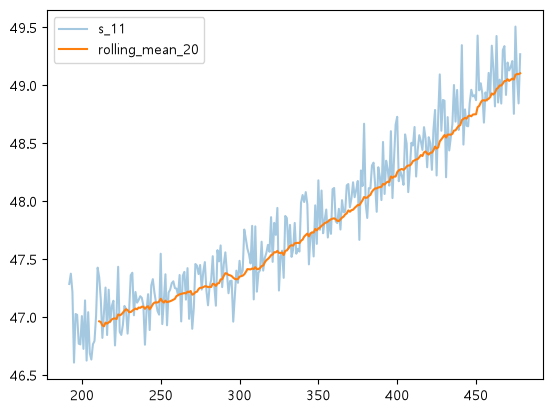

In [135]:
plt.plot(e2['s_11'], label='s_11', alpha=0.4)
plt.plot(e2['rolling_mean_20'], label='rolling_mean_20')
plt.legend()
plt.show()

In [ ]:
#실습5 

In [137]:
zc = ['s_4', 's_7', 's_11', 's_21']

In [138]:
# z 스코어 = (값 - 평균) / 표준편차


In [142]:
df_z = (df[zc] - df[zc].mean()) / df[zc].std()
df_z.head()

,s_4,s_7,s_11,s_21
0,-1.222995,1.231588,-1.334830,0.947867
1,-1.101613,1.020097,-1.150200,1.133697
2,-1.048678,0.952167,-1.220570,0.536725
3,-1.460845,0.660344,-0.873327,1.110894
4,-0.498835,1.043773,-1.152647,0.956716


In [145]:
df_z['s_11'].min()

np.float64(-1.870444829230602)

In [146]:
df_z['s_11'].max()

np.float64(2.4215223279333604)

In [ ]:
#실습6

In [ ]:
차분 =e2['s_11'].diff()


In [162]:
임계값 = 차분.abs().mean() + 3 * 차분.abs().std()

In [169]:
(차분.abs() > 임계값).sum()

np.int64(1)

In [174]:
e2_MA20 = e2['s_11'].rolling(20).mean()
e2_SD20 = e2['s_11'].rolling(20).std()

In [175]:
(e2['s_11'] > e2_MA20 + 2 * e2_SD20).sum()

np.int64(8)

In [176]:
#실습7

In [ ]:
# core = ['s_2', 's_4', 's_7', 's_11', 's_15', 's_21'

In [177]:
core = ['s_2', 's_4', 's_7', 's_11', 's_15', 's_21']

In [179]:
e2[core].corr()

,s_2,s_4,s_7,s_11,s_15,s_21
s_2,1.000000,0.846468,-0.873089,0.912029,0.896462,-0.879226
s_4,0.846468,1.000000,-0.839218,0.869239,0.859686,-0.870096
s_7,-0.873089,-0.839218,1.000000,-0.889745,-0.887118,0.874361
s_11,0.912029,0.869239,-0.889745,1.000000,0.912286,-0.903224
s_15,0.896462,0.859686,-0.887118,0.912286,1.000000,-0.892180
s_21,-0.879226,-0.870096,0.874361,-0.903224,-0.892180,1.000000


In [184]:
e2[['s_2','s_15']].corr()

,s_2,s_15
s_2,1.000000,0.896462
s_15,0.896462,1.000000


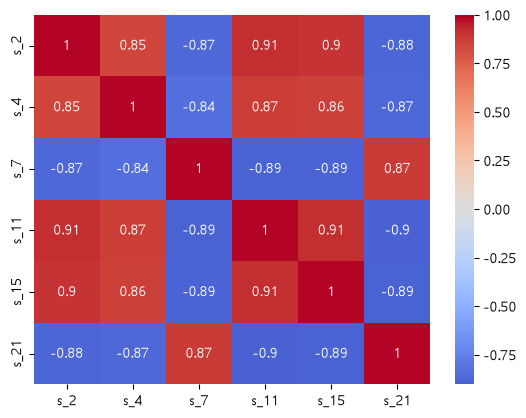

In [185]:
sns.heatmap(e2[core].corr(), annot=True, cmap='coolwarm', center=0)
plt.show()

In [188]:
z_score = (e2[core] - e2[core].mean()) / e2[core].std()
z_score

,s_2,s_4,s_7,s_11,s_15,s_21
192,-0.970963,-1.307206,1.013625,-0.783462,-1.386640,1.303425
193,-0.974724,-0.110171,0.874651,-0.658017,-0.707462,1.155967
194,-1.061585,-1.954524,1.678306,-0.879839,-1.717197,0.492224
195,-0.963199,-1.102349,0.991032,-1.740601,-1.209620,0.998104
196,-0.780378,-0.604976,2.394438,-1.149074,-1.019956,1.511518
...,...,...,...,...,...,...
474,1.742840,2.670598,-1.579315,1.288573,2.348838,-2.077718
475,1.964724,1.858057,-1.936147,2.350979,1.481802,-2.317741
476,1.876165,1.643355,-1.704334,1.733629,1.655210,-2.355413
477,1.781418,2.021403,-2.418567,1.415430,2.034538,-1.935282


In [195]:
(z_score.abs() > 2).sum(axis=1).max()

np.int64(3)

In [196]:
#실습 9 

In [ ]:
e2['']